In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier

In [2]:
columns = ["buying_price", "maintenance_cost", "number_of_doors",
           "number_of_persons", "lug_boot", "safety", "decision"]
df = pd.read_csv("car_evaluation.csv", header=None, names=columns)

print(df["decision"].value_counts())

decision
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64


In [ ]:
encoder = LabelEncoder()
df["decision"] = encoder.fit_transform(df["decision"])

X = pd.get_dummies(df.drop("decision", axis=1), dtype=int)
y = df["decision"]
print("X shape:", X.shape)

X shape: (1728, 21)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (1382, 21)  Test: (346, 21)


In [5]:
def evaluate(name, model, X_train, X_test, y_train, y_test):
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    cm = confusion_matrix(y_test, y_pred)
    ConfusionMatrixDisplay(cm, display_labels=model.classes_).plot()
    plt.title("Confusion Matrix - " + name)
    plt.show()

    result = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, average="weighted", zero_division=0),
        "Recall": recall_score(y_test, y_pred, average="weighted", zero_division=0),
        "F1-Score": f1_score(y_test, y_pred, average="weighted", zero_division=0),
    }
    print("=====", name, "=====")
    for metric, value in list(result.items())[1:]:
        print(f"{metric:10s}: {value:.4f}")
    return result

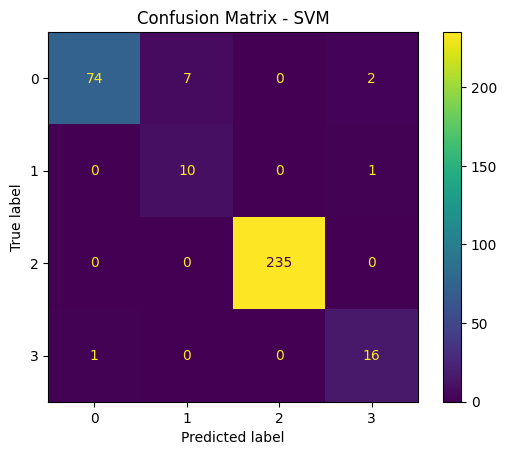

===== SVM =====
Accuracy  : 0.9682
Precision : 0.9760
Recall    : 0.9682
F1-Score  : 0.9703


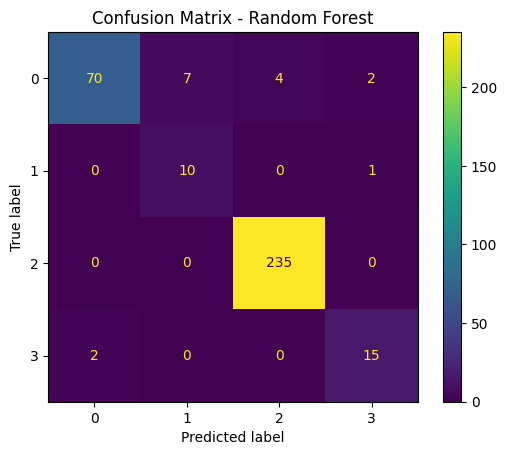

===== Random Forest =====
Accuracy  : 0.9538
Precision : 0.9607
Recall    : 0.9538
F1-Score  : 0.9550


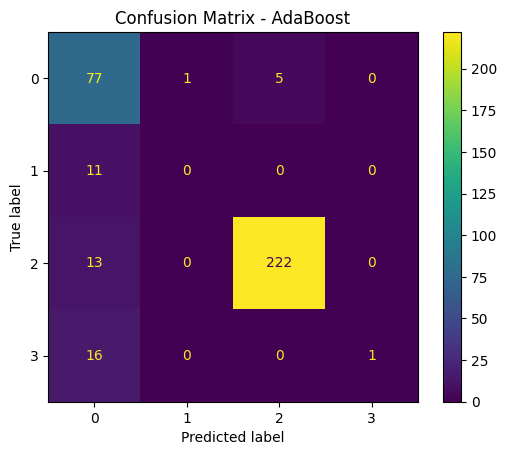

===== AdaBoost =====
Accuracy  : 0.8671
Precision : 0.8712
Recall    : 0.8671
F1-Score  : 0.8429


In [6]:
models = {
    "SVM": SVC(),
    "Random Forest": RandomForestClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42),
}

results = []
for name, model in models.items():
    results.append(evaluate(name, model, X_train, X_test, y_train, y_test))

In [7]:
# cross val (k = 5)

for name, model in models.items():
    scores = cross_val_score(model, X_train, y_train, cv=5)
    print(f"{name:14s} -> fold accuracies: {scores.round(3)}  mean: {scores.mean():.4f}")

SVM            -> fold accuracies: [0.946 0.975 0.989 0.989 0.967]  mean: 0.9732
Random Forest  -> fold accuracies: [0.953 0.971 0.953 0.975 0.935]  mean: 0.9573
AdaBoost       -> fold accuracies: [0.87  0.866 0.88  0.822 0.833]  mean: 0.8545


SVM best params: {'C': 10, 'kernel': 'rbf'}  best CV accuracy: 0.9935


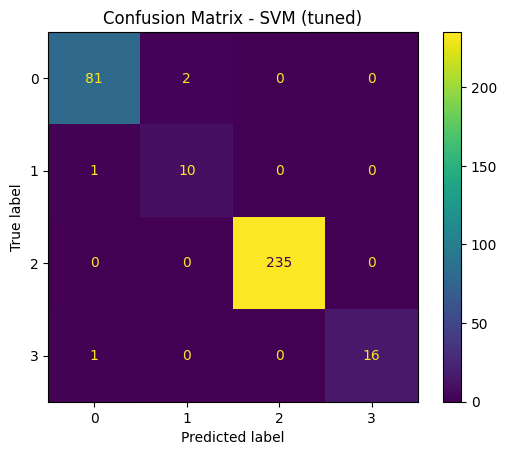

===== SVM (tuned) =====
Accuracy  : 0.9884
Precision : 0.9889
Recall    : 0.9884
F1-Score  : 0.9886
Random Forest best params: {'max_depth': None, 'n_estimators': 200}  best CV accuracy: 0.958


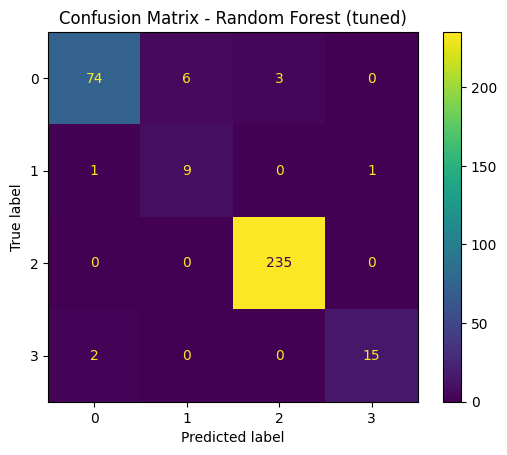

===== Random Forest (tuned) =====
Accuracy  : 0.9624
Precision : 0.9663
Recall    : 0.9624
F1-Score  : 0.9635
AdaBoost best params: {'learning_rate': 1.0, 'n_estimators': 200}  best CV accuracy: 0.8647


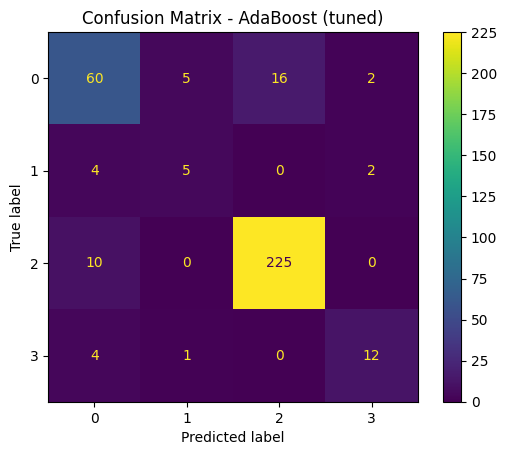

===== AdaBoost (tuned) =====
Accuracy  : 0.8728
Precision : 0.8699
Recall    : 0.8728
F1-Score  : 0.8711


In [ ]:
# hyper param

param_grids = {
    "SVM": {"C": [0.1, 1, 10], "kernel": ["linear", "rbf"]},
    "Random Forest": {"n_estimators": [50, 100, 200], "max_depth": [5, 10, 20]},
    "AdaBoost": {"n_estimators": [50, 100, 200], "learning_rate": [0.1, 1.0]},
}

for name, model in models.items():
    grid = GridSearchCV(model, param_grids[name], cv=5, n_jobs=-1)
    grid.fit(X_train, y_train)
    print(name, "best params:", grid.best_params_, " best CV accuracy:", round(grid.best_score_, 4))
    results.append(evaluate(name + " (tuned)", grid.best_estimator_, X_train, X_test, y_train, y_test))

                       Accuracy  Precision  Recall  F1-Score
Model                                                       
SVM                      0.9682     0.9760  0.9682    0.9703
Random Forest            0.9538     0.9607  0.9538    0.9550
AdaBoost                 0.8671     0.8712  0.8671    0.8429
SVM (tuned)              0.9884     0.9889  0.9884    0.9886
Random Forest (tuned)    0.9624     0.9663  0.9624    0.9635
AdaBoost (tuned)         0.8728     0.8699  0.8728    0.8711


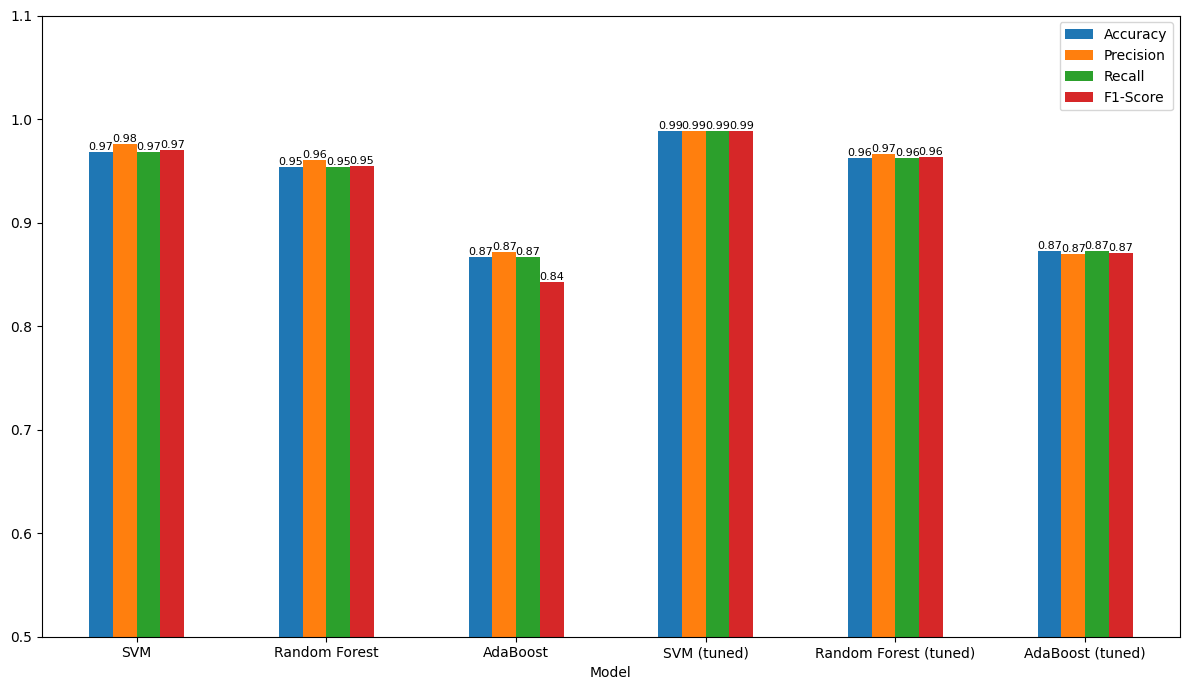

In [10]:
results_df = pd.DataFrame(results).set_index("Model")
print(results_df.round(4))

ax = results_df.plot(kind="bar", figsize=(12, 7), rot=0)

for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", fontsize=8)

plt.ylim(0.5, 1.1)
plt.tight_layout()
plt.show()

In [ ]:
# predict car decision from user input

user = {}
for col in columns[:-1]:
    opts = sorted(df[col].unique())
    val = input(f"{col} {opts}: ").strip()
    while val not in opts:
        val = input(f"  choose one of {opts}: ").strip()
    user[col] = val

# same one-hot columns as training (missing ones = 0)
user_X = pd.get_dummies(pd.DataFrame([user]), dtype=int).reindex(columns=X.columns, fill_value=0)

print("\nInput:", user)
for name, model in models.items():
    pred = encoder.inverse_transform(model.predict(user_X))[0]
    print(f"{name:14s} -> {pred}")